Homework 7, problem 3, part c

In [1]:
# libraries and parameters

import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import poisson, gamma, binom

np.random.seed(42)
lam = 4
t_max = 1
n_sim = 200000

In [2]:
max_gaps = 15 
gaps = np.random.exponential(scale = 1.0/lam, size = (n_sim, max_gaps))
arrival_times = np.cumsum(gaps, axis = 1)

# compute N(1) for each trial
N1_construction1 = np.sum(arrival_times <= t_max, axis = 1)

# extract statistics specifically for trials where N(1) == 3
mask_N3 = (N1_construction1 == 3)
arrival_times_N3 = arrival_times[mask_N3]

# counts in first half-hour [0, 0.5]
N_half_construction1 = np.sum(arrival_times_N3 <= 0.5, axis=1)
prob_N_half_zero = np.mean(N_half_construction1 == 0)

# expected time of first arrival given N(1) == 3
expected_T1_cond = np.mean(arrival_times_N3[:, 0])

# correlation between first and second half hour over all hours
N_first_half_all = np.sum(arrival_times <= 0.5, axis=1)
N_second_half_all = np.sum((arrival_times > 0.5) & (arrival_times <= 1.0), axis=1)
correlation_all = np.corrcoef(N_first_half_all, N_second_half_all)[0, 1]

In [3]:
N1_construction2 = np.random.poisson(lam * t_max, size=n_sim)
# to keep track of points for rasters, generate list of sorted arrays
uniform_arrivals = []
for n in N1_construction2[:10]:
    points = np.sort(np.random.uniform(0, t_max, size=n))
    uniform_arrivals.append(points)

print("Constructions comparisons")
print(f"Construction 1 (Gaps) -> Mean N(1): {np.mean(N1_construction1):.4f} | Variance: {np.var(N1_construction1):.4f}")
print(f"Construction 2 (Uniform) -> Mean N(1): {np.mean(N1_construction2):.4f} | Variance: {np.var(N1_construction2):.4f}")

print("Conditional estimates (given N(1) = 3)")
print(f"Estimated P(N(1/2) = 0 | N(1)=3) : {prob_N_half_zero:.4f} (Theoretical: 0.1250)")
print(f"Estimated E[T1 | N(1)=3] : {expected_T1_cond:.4f} (Theoretical: 0.2500)")
print(f"Correlation between half hours : {correlation_all:.4f} (Theoretical: 0.0000)")

Constructions comparisons
Construction 1 (Gaps) -> Mean N(1): 4.0033 | Variance: 4.0042
Construction 2 (Uniform) -> Mean N(1): 4.0026 | Variance: 3.9880
Conditional estimates (given N(1) = 3)
Estimated P(N(1/2) = 0 | N(1)=3) : 0.1249 (Theoretical: 0.1250)
Estimated E[T1 | N(1)=3] : 0.2492 (Theoretical: 0.2500)
Correlation between half hours : -0.0008 (Theoretical: 0.0000)


In [4]:
delta_t_vals = 1.0 / np.arange(10, 2001, 50)
tv_distances = []

for dt in delta_t_vals:
    n_steps = int(1.0 / dt)
    p_binom = lam * dt
    
    # evaluate support values up to a reasonable upper bound
    support = np.arange(0, 25)
    pmf_binom = binom.pmf(support, n_steps, p_binom)
    pmf_poiss = poisson.pmf(support, lam * t_max)
    
    # total variation distance definition
    tvd = 0.5 * np.sum(np.abs(pmf_binom - pmf_poiss))
    tv_distances.append(tvd)

# linear fit in log-log scale
slope, intercept = np.polyfit(np.log(delta_t_vals), np.log(tv_distances), 1)
print(f"Fitted slope on log-log axis: {slope:.4f} (Expected convergence: ~1.0)")

Fitted slope on log-log axis: 1.0208 (Expected convergence: ~1.0)


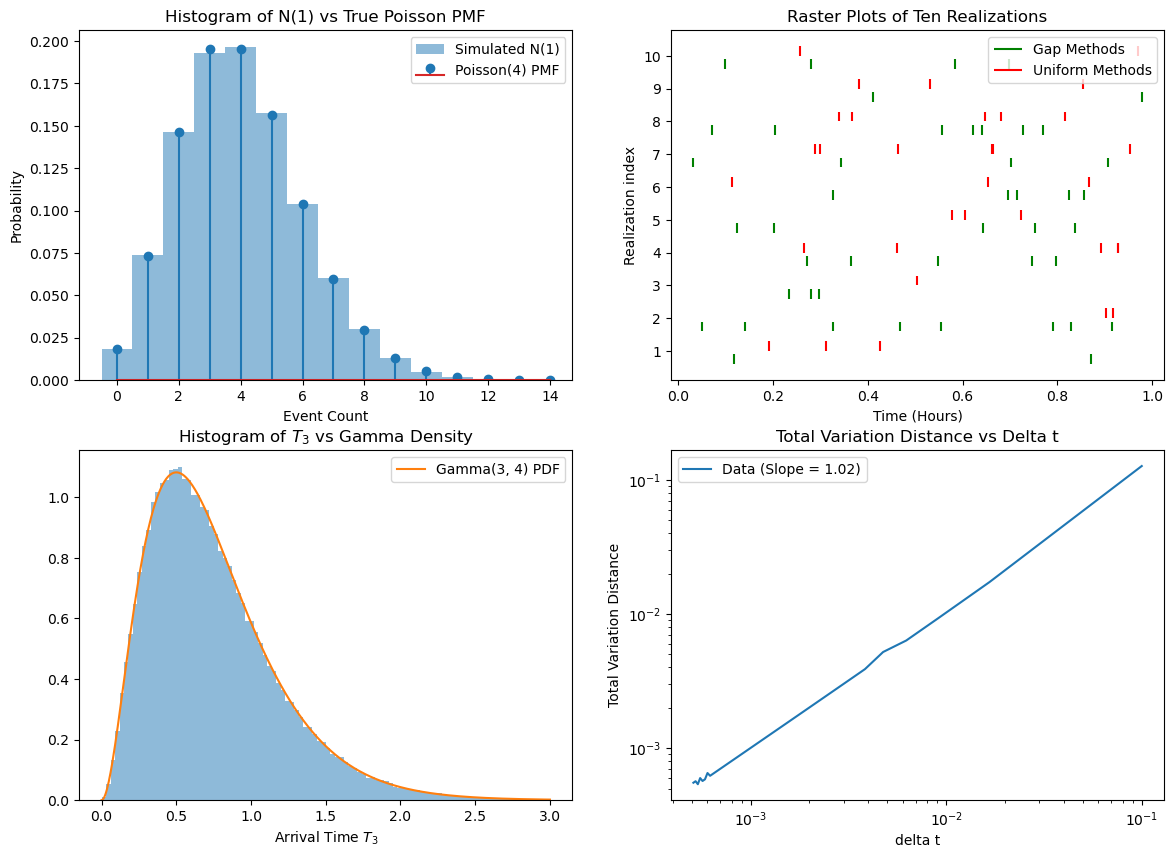

In [5]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# Histogram vs Poisson PMF
bins = np.arange(0, 15) - 0.5
axes[0, 0].hist(N1_construction1, bins = bins, density=True, alpha=0.5, label = 'Simulated N(1)')
axes[0, 0].stem(np.arange(15), poisson.pmf(np.arange(15), 4), label = 'Poisson(4) PMF')
axes[0, 0].set_title('Histogram of N(1) vs True Poisson PMF')
axes[0, 0].set_xlabel('Event Count')
axes[0, 0].set_ylabel('Probability')
axes[0, 0].legend()

# Raster plots of 10 realizations
for idx in range(10):
    # construction 1 rasters
    times_c1 = arrival_times[idx][arrival_times[idx] <= t_max]
    axes[0, 1].vlines(times_c1, idx + 0.1, idx + 0.4, color = "green", label = 'Gap Methods' if idx==0 else "")
    # construction 2 rasters
    times_c2 = uniform_arrivals[idx]
    axes[0, 1].vlines(times_c2, idx + 0.5, idx + 0.8, color = "red", label = 'Uniform Methods' if idx==0 else "")

axes[0, 1].set_title('Raster Plots of Ten Realizations')
axes[0, 1].set_xlabel('Time (Hours)')
axes[0, 1].set_ylabel('Realization index')
axes[0, 1].set_yticks(np.arange(10) + 0.5)
axes[0, 1].set_yticklabels(np.arange(1, 11))
axes[0, 1].legend()

# Histogram of T3 vs Gamma Density
# filter out paths where fewer than 3 arrivals occurred overall
valid_T3 = arrival_times[:, 2][np.sum(arrival_times <= 5.0, axis=1) >= 3]
axes[1, 0].hist(valid_T3, bins=100, range=(0, 3), density=True, alpha=0.5)
t_vars = np.linspace(0, 3, 500)
axes[1, 0].plot(t_vars, gamma.pdf(t_vars, a=3, scale=1.0/lam), label = 'Gamma(3, 4) PDF')
axes[1, 1].set_ylabel('Density')
axes[1, 0].set_title('Histogram of $T_3$ vs Gamma Density')
axes[1, 0].set_xlabel('Arrival Time $T_3$')
axes[1, 0].legend()

# TVD Convergence Log-Log Plot
axes[1, 1].loglog(delta_t_vals, tv_distances, label = f'Data (Slope = {slope:.2f})')
axes[1, 1].set_title('Total Variation Distance vs Delta t')
axes[1, 1].set_xlabel('delta t')
axes[1, 1].set_ylabel('Total Variation Distance')
axes[1, 1].legend()

plt.show()